# **Tasks**
# 1. Load the dataset using Pandas.

In [236]:
import pandas as pd
data=pd.read_csv("diabetes.csv")
data.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


# 2. Explore the dataset:

a. Shape of the dataset

In [237]:
print(data.shape)

(768, 9)


 b. Column names

In [238]:
data.columns.to_list()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

c. Data types

In [239]:
data.dtypes.to_dict()

{'Pregnancies': dtype('int64'),
 'Glucose': dtype('int64'),
 'BloodPressure': dtype('int64'),
 'SkinThickness': dtype('int64'),
 'Insulin': dtype('int64'),
 'BMI': dtype('float64'),
 'DiabetesPedigreeFunction': dtype('float64'),
 'Age': dtype('int64'),
 'Outcome': dtype('int64')}

d. Missing values, if any

In [240]:
data.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


e. Basic statistical summary

In [241]:
summary = data.describe().T.round(1)
print(summary)

                          count   mean    std   min   25%    50%    75%    max
Pregnancies               768.0    3.8    3.4   0.0   1.0    3.0    6.0   17.0
Glucose                   768.0  120.9   32.0   0.0  99.0  117.0  140.2  199.0
BloodPressure             768.0   69.1   19.4   0.0  62.0   72.0   80.0  122.0
SkinThickness             768.0   20.5   16.0   0.0   0.0   23.0   32.0   99.0
Insulin                   768.0   79.8  115.2   0.0   0.0   30.5  127.2  846.0
BMI                       768.0   32.0    7.9   0.0  27.3   32.0   36.6   67.1
DiabetesPedigreeFunction  768.0    0.5    0.3   0.1   0.2    0.4    0.6    2.4
Age                       768.0   33.2   11.8  21.0  24.0   29.0   41.0   81.0
Outcome                   768.0    0.3    0.5   0.0   0.0    0.0    1.0    1.0


# 3. Separate the dataset

 a. Features (X)

In [242]:
data['Has_Negative'] = (data < 0).any(axis=1)
data['Has_Negative'].value_counts()
data=data.drop(['Has_Negative'], axis=1)
data.head(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1


In [243]:
x=data.drop(['Outcome'],axis=1)
x.head(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50


b. Target Variable (y)

In [244]:
y=data['Outcome']
y.head(1)

,Outcome
0,1


# 4. Perform a Train-Test Split.

In [245]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.85)

## 5. Model selection and training

**Why LogisticRegression** :
Logistic Regression is designed for binary classification tasks—predicting exactly one of two outcomes, in this case predicts a person can have diabetes (1) or not (0).

*   High Interpretability: Logistic Regression allows you to inspect the coefficients to see exactly how much a specific feature (like Glucose or BMI) influences the final prediction.
*   Resistant to Overfitting




In [246]:
from numpy import mean
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model= Pipeline([("impute", SimpleImputer(strategy=mean)),
 ("scaler transform", StandardScaler()),
 ("model",LogisticRegression(max_iter=500))])
model.fit(x_train,y_train)


Pipeline(steps=[('impute',
                 SimpleImputer(strategy=<function mean at 0x7e74d3a1d8b0>)),
                ('scaler transform', StandardScaler()),
                ('model', LogisticRegression(max_iter=500))])

In [247]:
predictions_test = model.predict(x_test)
len(predictions_test)

116

# Train and Test Accuracy

In [248]:
from sklearn.metrics import accuracy_score
test_accuracy = accuracy_score(y_test,predictions_test)
predictions_train = model.predict(x_train)
train_accuracy = accuracy_score(y_train,predictions_train)
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")

Training Accuracy: 0.7853
Testing Accuracy:  0.7672


# Classification Report

In [252]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
print(classification_report(y_test,predictions_test))

              precision    recall  f1-score   support

           0       0.81      0.85      0.83        78
           1       0.66      0.61      0.63        38

    accuracy                           0.77       116
   macro avg       0.74      0.73      0.73       116
weighted avg       0.76      0.77      0.76       116



# Confusion Matrix

In [250]:
matrix = confusion_matrix(y_test,predictions_test)
matrix

array([[66, 12],
       [15, 23]])

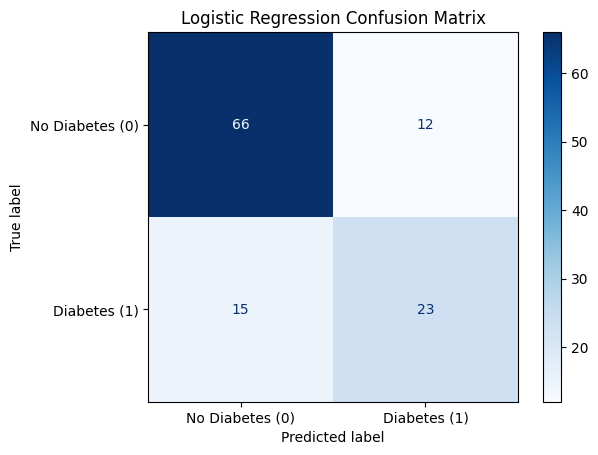

In [251]:
display = ConfusionMatrixDisplay(matrix, display_labels=['No Diabetes (0)', 'Diabetes (1)'])
display.plot(cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

**Key Conclusions**:

The model is highly effective at identifying healthy patients, successfully categorizing 66 of the 78 actual "No Diabetes" cases. However, it struggles to detect the positive class, capturing only 23 of the 38 actual "Diabetes" cases.**